In [1]:
pip install opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



Processing: Picture1.png


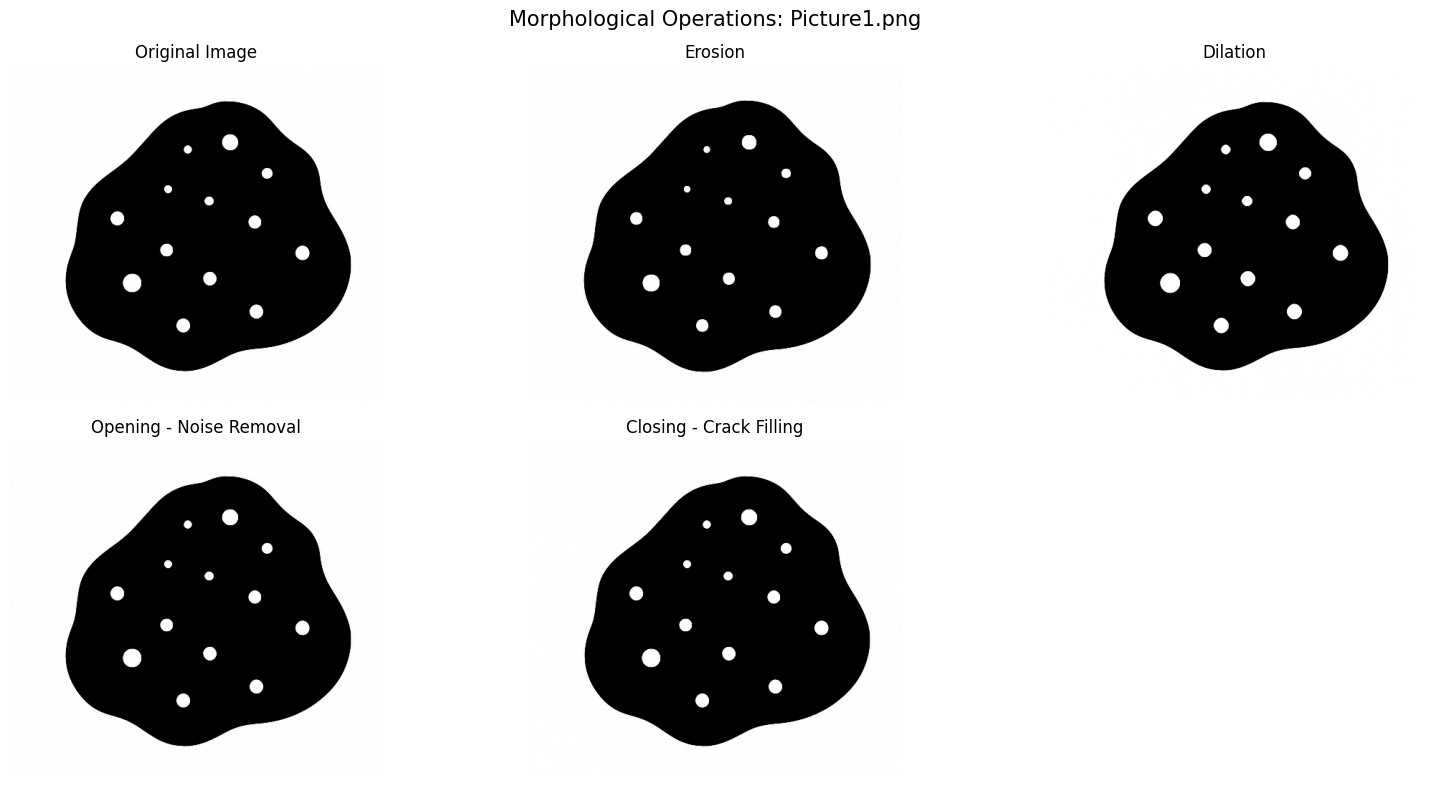

Successfully processed: Picture1.png

Processing: Picture2.png


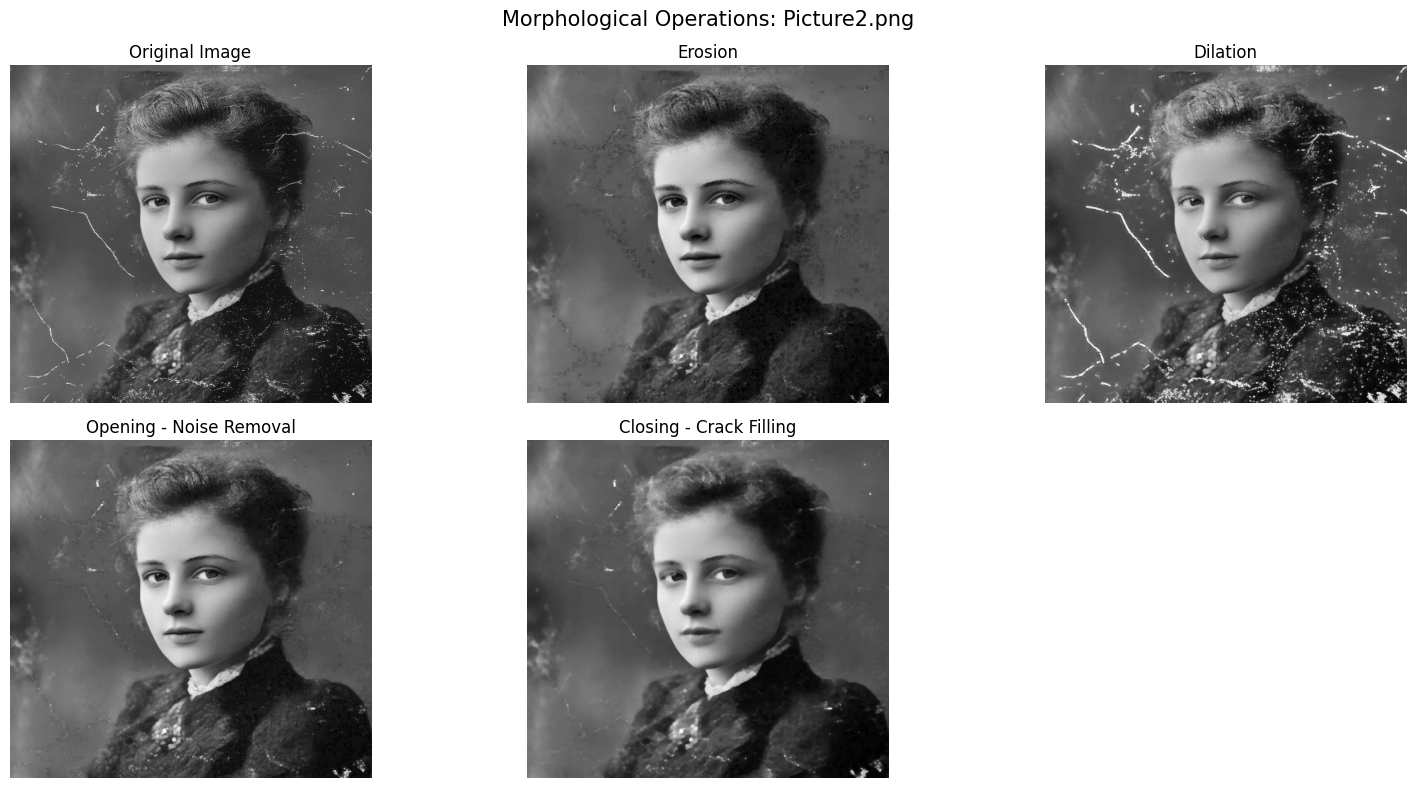

Successfully processed: Picture2.png

Processing: Picture3.png


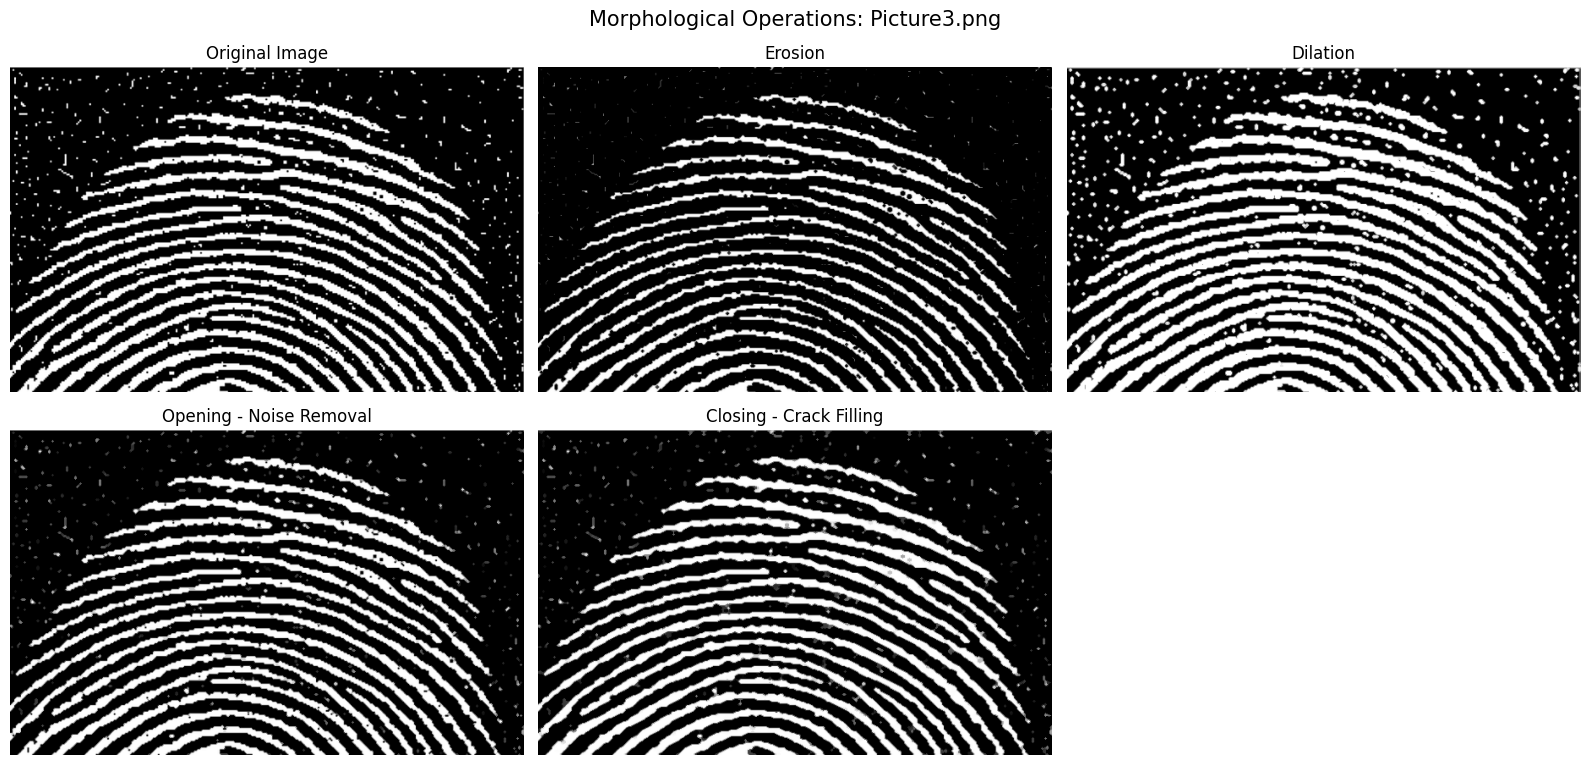

Successfully processed: Picture3.png

EXPERIMENT 6 COMPLETED SUCCESSFULLY
Output folder: D:\Sem_5\DSIP\Practical_Code\OEP_6\Output


In [3]:

# ============================================================
# EXPERIMENT 6: MORPHOLOGICAL IMAGE PROCESSING
# Aim:
# Remove small bright noise, fill narrow dark cracks,
# and preserve the overall shape of objects.
#
# Operations:
# 1. Erosion
# 2. Dilation
# 3. Opening
# 4. Closing
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# STEP 1: SET INPUT AND OUTPUT FOLDERS
# ------------------------------------------------------------

INPUT_FOLDER = Path.cwd()
OUTPUT_FOLDER = INPUT_FOLDER / "Output"

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

image_names = [
    "Picture1.png",
    "Picture2.png",
    "Picture3.png"
]

# ------------------------------------------------------------
# STEP 2: DEFINE STRUCTURING ELEMENTS
# ------------------------------------------------------------

# Small kernel for removing bright noise
opening_kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

# Kernel for filling narrow dark cracks
closing_kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

# ------------------------------------------------------------
# STEP 3: PROCESS ALL THREE IMAGES
# ------------------------------------------------------------

for image_name in image_names:

    print("\nProcessing:", image_name)

    image_path = INPUT_FOLDER / image_name

    # Read original image
    original = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    # Check image availability
    if original is None:
        print("ERROR: Image not found:", image_path)
        continue

    # --------------------------------------------------------
    # STEP 4: EROSION
    # --------------------------------------------------------

    erosion = cv2.erode(
        original,
        opening_kernel,
        iterations=1
    )

    # --------------------------------------------------------
    # STEP 5: DILATION
    # --------------------------------------------------------

    dilation = cv2.dilate(
        original,
        opening_kernel,
        iterations=1
    )

    # --------------------------------------------------------
    # STEP 6: OPENING
    # Removes small bright noise
    # Opening = Erosion followed by Dilation
    # --------------------------------------------------------

    opening = cv2.morphologyEx(
        original,
        cv2.MORPH_OPEN,
        opening_kernel,
        iterations=1
    )

    # --------------------------------------------------------
    # STEP 7: CLOSING
    # Fills narrow dark cracks and gaps
    # Closing = Dilation followed by Erosion
    # --------------------------------------------------------

    closing = cv2.morphologyEx(
        opening,
        cv2.MORPH_CLOSE,
        closing_kernel,
        iterations=1
    )

    # --------------------------------------------------------
    # STEP 8: SAVE PROCESSED IMAGES
    # --------------------------------------------------------

    cv2.imwrite(
        str(OUTPUT_FOLDER / f"Processed_{image_name}"),
        closing
    )

    # --------------------------------------------------------
    # STEP 9: DISPLAY RESULTS
    # --------------------------------------------------------

    images = [
        original,
        erosion,
        dilation,
        opening,
        closing
    ]

    titles = [
        "Original Image",
        "Erosion",
        "Dilation",
        "Opening - Noise Removal",
        "Closing - Crack Filling"
    ]

    plt.figure(figsize=(16, 8))

    for i in range(len(images)):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle(
        f"Morphological Operations: {image_name}",
        fontsize=15
    )

    plt.tight_layout()

    # Save comparison figure
    plt.savefig(
        str(OUTPUT_FOLDER / f"Comparison_{image_name}"),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Successfully processed:", image_name)

# ------------------------------------------------------------
# STEP 10: FINAL STATUS
# ------------------------------------------------------------

print("\n===================================")
print("EXPERIMENT 6 COMPLETED SUCCESSFULLY")
print("===================================")
print("Output folder:", OUTPUT_FOLDER.resolve())
